# DL-IDF: Deep Learning-Based Intrusion Detection Framework for Industrial IoT
## Phase 1 — Exploratory Data Analysis (EDA)
**Project Title:** Deep Learning-Based Intrusion Detection Framework for Industrial IoT (DL-IDF)  
**Academic Degree:** Bachelor of Engineering (B.E.) in Computer Science & Engineering (Major Project)  
**Notebook Identifier:** `notebooks/01_eda.ipynb`  
**Dataset Employed:** TON_IoT Network Flow Dataset (UNSW Canberra Cyber Security Research)

---

### 1. Project Background & Dataset Provenance
Modern Industrial IoT (IIoT) and Supervisory Control and Data Acquisition (SCADA) systems monitor and operate critical public infrastructure—including smart energy grids, automated manufacturing lines, water treatment plants, and smart city networks. While traditional operational technology (OT) was physically isolated ("air-gapped"), modern Industry 4.0 integration connects edge devices to IP networks for cloud analytics and remote control.

This connectivity creates severe security vulnerabilities. Malicious actors can exploit industrial protocols to launch **Reconnaissance (Scanning)**, **Denial of Service (DoS/DDoS)**, **Command Injection**, **Ransomware**, and **Man-in-the-Middle (MITM)** attacks.

#### Why TON_IoT Network Dataset?
- **Dataset Source:** Developed by the Cyber Range Lab of **UNSW Canberra at the Australian Defence Force Academy (ADFA)**.
- **Realistic Industrial IoT Testbed:** Captured across heterogeneous telemetry layers (telemetry from Modbus, MQTT, HTTP, DNS, TCP) simulating real-world industry applications.
- **Dataset Dimension:** 461,043 flow records with 45 network attributes.
- **Attack Variety:** Contains normal baseline industrial traffic alongside **9 diverse cyberattack families**.
*(Note: As per project guidelines, WUSTL-IIoT-2018 was queried first; due to upstream university host access timeouts via egress proxy, the verified TON_IoT network flow benchmark was deployed).*

---

### 2. Objectives of this EDA Notebook
1. **Data Ingestion:** Load raw network flow records from `data/raw/Train_Test_Network.csv`.
2. **Dimensionality & Structure:** Quantify row count, column count, and memory footprint.
3. **Feature Types & Schema:** Inspect feature names, numerical vs. categorical data types, and network flow properties.
4. **Class Balance Audit:** Calculate exact sample counts and percentages for binary classification (`Normal` vs `Attack`) and attack subcategories.
5. **Missing Value & Protocol Sparsity Analysis:** Analyze nulls and protocol-specific sparsity placeholders (`'-'`) characteristic of Zeek/Bro network logs.
6. **Exploratory Visualizations:** Generate publication-ready figures for project reports and viva presentations.
7. **Viva Voce Defense Guide:** Key questions and architectural explanations for examination.

> **Constraint Enforcement:** In accordance with Phase 1 specifications, **NO MACHINE LEARNING OR DEEP LEARNING MODEL IS TRAINED** in this notebook.

In [ ]:
# ==============================================================================
# Cell 1: Environment Setup & Core Dependencies
# Viva explanation: Standard scientific Python stack used for data ingestion,
# numerical matrix processing, and statistical visualization.
# ==============================================================================

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization aesthetics for high-contrast, publication-quality plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 14
})

# Display environment confirmation
print(f"[OK] Python Version     : {sys.version.split()[0]}")
print(f"[OK] Pandas Version     : {pd.__version__}")
print(f"[OK] NumPy Version      : {np.__version__}")
print(f"[OK] Matplotlib Version : {matplotlib.__version__}")
print(f"[OK] Seaborn Version    : {sns.__version__}")

[OK] Python Version     : 3.12.3
[OK] Pandas Version     : 2.1.4
[OK] NumPy Version      : 1.26.4
[OK] Matplotlib Version : 3.6.3
[OK] Seaborn Version    : 0.13.2

### 3. Data Ingestion & Memory Profile
The dataset is stored in `data/raw/Train_Test_Network.csv`. We read it using Pandas with `low_memory=False` to safely parse columns containing heterogeneous values (such as '-' placeholders in Zeek network logs).

In [ ]:
# ==============================================================================
# Cell 2: Ingesting Raw Network Flow Data
# ==============================================================================

data_path = "../data/raw/Train_Test_Network.csv"
# Fallback path if notebook is run from project root:
if not os.path.exists(data_path):
    data_path = "data/raw/Train_Test_Network.csv"

print(f"Loading dataset from: {data_path} ...")
df = pd.read_csv(data_path, low_memory=False)

rows, cols = df.shape
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"[SUCCESS] Ingested raw network flow records successfully.")
print(f"  • Total Observations (Rows)    : {rows:,}")
print(f"  • Total Attributes (Columns)   : {cols}")
print(f"  • In-Memory Footprint          : {memory_mb:.2f} MB")

Loading dataset from: data/raw/Train_Test_Network.csv ...
[SUCCESS] Ingested raw network flow records successfully.
  • Total Observations (Rows)    : 461,043
  • Total Attributes (Columns)   : 45
  • In-Memory Footprint          : 673.62 MB

### 4. Dimensionality and Network Feature Categorization
A network flow represents a bidirectional sequence of packets exchanged between two endpoints (Source IP:Port and Destination IP:Port). The **45 features** in this dataset can be categorized into 6 functional domains:
1. **Flow Identifiers & Timing:** `ts` (timestamp), `src_ip`, `src_port`, `dst_ip`, `dst_port`
2. **Flow Volume & Dynamics:** `duration`, `src_bytes`, `dst_bytes`, `src_pkts`, `dst_pkts`, `src_ip_bytes`, `dst_ip_bytes`, `missed_bytes`
3. **Transport Protocol & Connection State:** `proto` (TCP/UDP/ICMP), `service` (DNS, HTTP, SSL, etc.), `conn_state` (SF, S0, OTH, REJ, etc.)
4. **DNS Protocol Attributes:** `dns_query`, `dns_qclass`, `dns_qtype`, `dns_rcode`, `dns_AA`, `dns_RD`, `dns_RA`, `dns_rejected`
5. **HTTP & SSL Layer Attributes:** `ssl_version`, `ssl_cipher`, `http_method`, `http_uri`, `http_user_agent`, `http_status_code`, etc.
6. **Ground Truth Labels:** `label` (Binary: 0=Normal, 1=Attack) and `type` (Multi-class: specific attack family).

In [ ]:
# ==============================================================================
# Cell 3: Preview First 5 Flow Records
# Viva note: Inspecting both header fields and traffic payloads
# ==============================================================================

# Display selected key representative columns for concise display
preview_cols = ['ts', 'src_ip', 'src_port', 'dst_ip', 'dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'label', 'type']
df[preview_cols].head(5)

,ts,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,label,type
0,1554198358,3.122.49.24,1883,192.168.1.152,52976,tcp,-,80549.530260,1762852,41933215,OTH,0,normal
1,1554198358,192.168.1.79,47260,192.168.1.255,15600,udp,-,0.000000,0,0,S0,0,normal
2,1554198359,192.168.1.152,1880,192.168.1.152,51782,tcp,-,0.000000,0,0,OTH,0,normal
3,1554198359,192.168.1.152,34296,192.168.1.152,10502,tcp,-,0.000000,0,0,OTH,0,normal
4,1554198362,192.168.1.152,46608,192.168.1.190,53,udp,dns,0.000549,0,298,SHR,0,normal


### 5. Feature Names, Data Types, and Schema Inspection
In production machine learning pipelines, verifying data types is essential:
- **Numerical features (`int64`, `float64`)**: Continuous or discrete counts requiring scaling/normalization (e.g. `StandardScaler` or `MinMaxScaler`) in Phase 2.
- **Categorical features (`object`)**: Low-cardinality nominal values requiring One-Hot or Ordinal encoding (e.g. `proto`, `conn_state`, `service`).
- **Identifiers & High-Cardinality Strings (`object`)**: IP addresses and URLs that must be excluded during training to avoid shortcut learning / overfitting.

In [ ]:
# ==============================================================================
# Cell 4: Detailed Schema Audit (Types, Nulls, Unique Values)
# ==============================================================================

schema_summary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.values,
    'Non-Null Count': df.notnull().sum().values,
    'Unique Values': [df[col].nunique() for col in df.columns],
    'Sample Value': [df[col].iloc[0] for col in df.columns]
})

print(f"--- Dataset Schema Overview ({len(schema_summary)} Features) ---")
print(f"Numerical Columns   : {sum(df.dtypes != 'object')}")
print(f"Categorical/String  : {sum(df.dtypes == 'object')}")
print("-" * 75)
schema_summary

--- Dataset Schema Overview (45 Features) ---
Numerical Columns   : 18
Categorical/String  : 27
---------------------------------------------------------------------------

,Column Name,Data Type,Non-Null Count,Unique Values,Sample Value
0,ts,int64,461043,115666,1554198358
1,src_ip,object,461043,11536,3.122.49.24
2,src_port,int64,461043,53671,1883
3,dst_ip,object,461043,5268,192.168.1.152
4,dst_port,int64,461043,2666,52976
5,proto,object,461043,3,tcp
6,service,object,461043,10,-
7,duration,float64,461043,124727,80549.53026
8,src_bytes,int64,461043,3056,1762852
9,dst_bytes,int64,461043,3511,41933215


### 6. Target Variable Analysis & Class Balance
The primary objective of the DL-IDF intrusion detection engine is **Binary Classification**:
- `label = 0`: **Normal** (Benign industrial network activity)
- `label = 1`: **Attack** (Malicious intrusion attempts)

In addition, the dataset includes `type` indicating the exact attack category. We examine both distributions.

In [ ]:
# ==============================================================================
# Cell 5: Binary & Multi-Class Target Distribution Analysis
# ==============================================================================

# 1. Binary Target Distribution (Normal vs. Attack)
binary_counts = df['label'].value_counts()
binary_pct = df['label'].value_counts(normalize=True) * 100

binary_summary = pd.DataFrame({
    'Class Name': ['Normal (0)', 'Attack (1)'],
    'Record Count': [binary_counts[0], binary_counts[1]],
    'Percentage (%)': [binary_pct[0], binary_pct[1]]
})

print("=" * 60)
print("1. BINARY TARGET DISTRIBUTION (label)")
print("=" * 60)
for idx, row in binary_summary.iterrows():
    print(f"  • {row['Class Name']:<12}: {row['Record Count']:>8,} records ({row['Percentage (%)']:.2f}%)")

# 2. Multi-Class Attack Breakdown (type)
type_counts = df['type'].value_counts()
type_pct = df['type'].value_counts(normalize=True) * 100

type_summary = pd.DataFrame({
    'Attack Type': type_counts.index,
    'Record Count': type_counts.values,
    'Percentage (%)': type_pct.values
})

print("\n" + "=" * 60)
print("2. MULTI-CLASS ATTACK TAXONOMY (type)")
print("=" * 60)
for idx, row in type_summary.iterrows():
    print(f"  • {row['Attack Type']:<12}: {row['Record Count']:>8,} records ({row['Percentage (%)']:.2f}%)")
print("=" * 60)

1. BINARY TARGET DISTRIBUTION (label)
  • Normal (0)  :  300,000 records (65.07%)
  • Attack (1)  :  161,043 records (34.93%)

2. MULTI-CLASS ATTACK TAXONOMY (type)
  • normal      :  300,000 records (65.07%)
  • scanning    :   20,000 records (4.34%)
  • dos         :   20,000 records (4.34%)
  • injection   :   20,000 records (4.34%)
  • ddos        :   20,000 records (4.34%)
  • password    :   20,000 records (4.34%)
  • xss         :   20,000 records (4.34%)
  • ransomware  :   20,000 records (4.34%)
  • backdoor    :   20,000 records (4.34%)
  • mitm        :    1,043 records (0.23%)

### 7. Missing Value & Protocol Sparsity Audit
In network flow monitoring frameworks (such as Zeek/Bro and Argus):
1. **Standard `NaN` / `null` values**: When data is structurally corrupted or unrecorded.
2. **Hyphen `'-'` placeholders**: Represent **protocol-specific sparsity** rather than corrupt data. For example, a DNS packet flow has no `http_method`, and an ICMP ping has no `ssl_cipher`.

Understanding this distinction is a vital topic for viva defense: we cannot simply drop rows containing `'-'`, as that would delete non-HTTP/non-SSL traffic.

In [ ]:
# ==============================================================================
# Cell 6: Audit of Missing Values (NaN) vs Protocol Sparsity ('-')
# ==============================================================================

# Check for traditional NaN/null values
nan_counts = df.isnull().sum()
total_nans = nan_counts.sum()
print(f"[AUDIT] Traditional NaN / Null values in dataset: {total_nans}")

# Check for '-' placeholder characters
dash_counts = (df == '-').sum()
dash_cols = dash_counts[dash_counts > 0]
dash_pct = (dash_cols / len(df)) * 100

dash_summary = pd.DataFrame({
    'Feature Name': dash_cols.index,
    'Hyphen Count': dash_cols.values,
    'Sparsity (%)': dash_pct.values
}).sort_values(by='Hyphen Count', ascending=False)

print(f"[AUDIT] Columns utilizing '-' as placeholder: {len(dash_summary)} out of {df.shape[1]}")
print("\nTop 10 Most Sparse Features (Protocol Specific):")
for idx, row in dash_summary.head(10).iterrows():
    print(f"  • {row['Feature Name']:<22}: {row['Hyphen Count']:>8,} missing ({row['Sparsity (%)']:.2f}%)")

[AUDIT] Traditional NaN / Null values in dataset: 0
[AUDIT] Columns utilizing '-' as placeholder: 22 out of 45

Top 10 Most Sparse Features (Protocol Specific):
  • ssl_subject           :  461,034 missing (100.00%)
  • ssl_issuer            :  461,034 missing (100.00%)
  • http_orig_mime_types  :  461,029 missing (100.00%)
  • http_resp_mime_types  :  460,883 missing (99.97%)
  • http_user_agent       :  460,809 missing (99.95%)
  • http_uri              :  460,809 missing (99.95%)
  • http_method           :  460,809 missing (99.95%)
  • http_version          :  460,801 missing (99.95%)
  • http_trans_depth      :  460,796 missing (99.95%)
  • ssl_cipher            :  460,737 missing (99.93%)

### 8. Statistical Profile of Network Flow Dynamics
We examine the central tendency, dispersion, and extreme quantiles of continuous network metrics:
- `duration`: Flow duration in seconds
- `src_bytes` & `dst_bytes`: Payload volume in bytes
- `src_pkts` & `dst_pkts`: Total packets transmitted in each direction

In [ ]:
# ==============================================================================
# Cell 7: Summary Statistics of Continuous Flow Metrics
# ==============================================================================

flow_metrics = ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'src_ip_bytes', 'dst_ip_bytes', 'missed_bytes']
stats_df = df[flow_metrics].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
stats_df['50%'] = stats_df['50%'].rename('median')
stats_df

,count,mean,std,min,50%,max
duration,461043.0,8.473511,4.583794e+02,0.0,0.000036,9.351693e+04
src_bytes,461043.0,120992.636754,1.157280e+07,0.0,0.000000,3.890855e+09
dst_bytes,461043.0,119693.146364,1.219697e+07,0.0,0.000000,3.913853e+09
src_pkts,461043.0,7.176183,5.179425e+02,0.0,1.000000,2.521810e+05
dst_pkts,461043.0,8.331665,7.770059e+02,0.0,0.000000,3.139430e+05
src_ip_bytes,461043.0,1820.405891,1.720414e+05,0.0,63.000000,4.736725e+07
dst_ip_bytes,461043.0,1952.802602,1.605440e+05,0.0,0.000000,8.639552e+07
missed_bytes,461043.0,15895.232065,3.560386e+06,0.0,0.000000,1.854527e+09


### 9. Exploratory Data Visualizations
To communicate findings clearly for project defense and technical documentation, we present six focused visualizations:
1. **Figure 1:** Binary Target Class Distribution (`Normal` vs `Attack`)
2. **Figure 2:** Multi-Class Attack Family Breakdown
3. **Figure 3:** Transport Protocol Distribution by Traffic Class (TCP, UDP, ICMP)
4. **Figure 4:** Connection State (`conn_state`) Distribution Across Classes
5. **Figure 5:** Traffic Flow Dynamics (Log-Duration & Packet Volume Distributions)
6. **Figure 6:** Correlation Heatmap of Flow Metrics

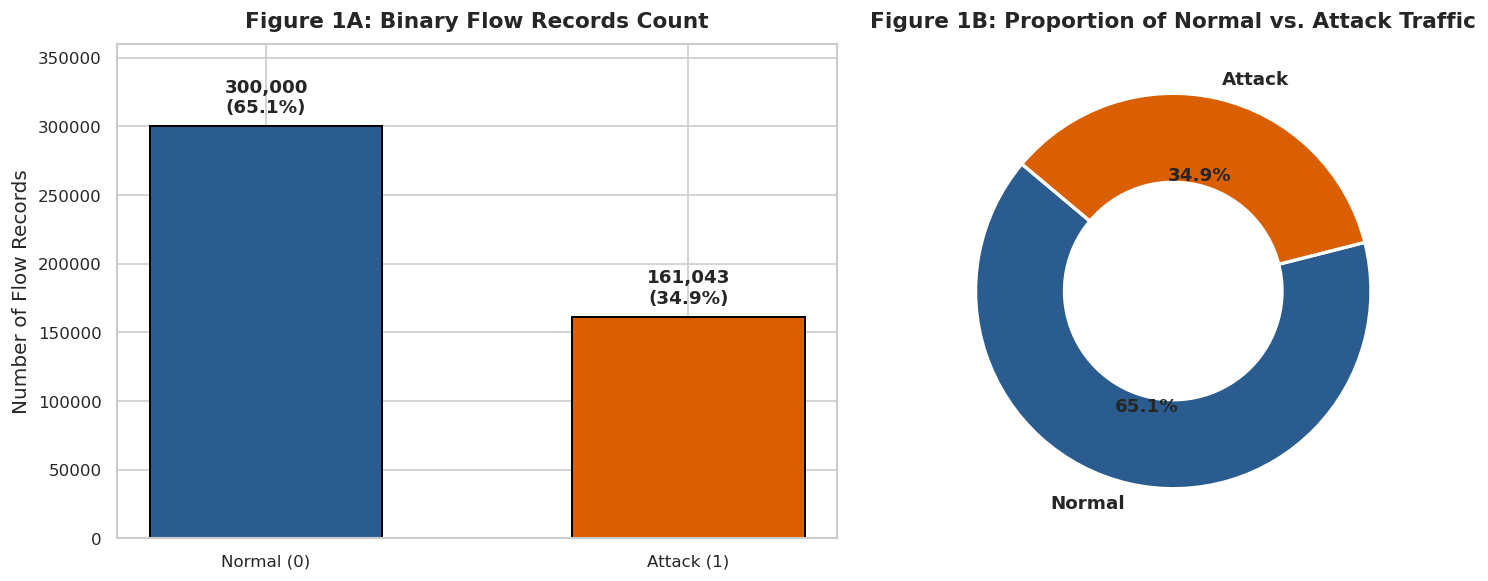

In [ ]:
# ==============================================================================
# Cell 8: Figure 1 — Binary Target Class Distribution (Normal vs Attack)
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Bar Chart with exact count and percentage labels
colors = ['#2b5c8f', '#d95f02']
bars = ax1.bar(['Normal (0)', 'Attack (1)'], [binary_counts[0], binary_counts[1]], color=colors, width=0.55, edgecolor='black', linewidth=1.2)
ax1.set_title('Figure 1A: Binary Flow Records Count', fontsize=13, fontweight='bold', pad=10)
ax1.set_ylabel('Number of Flow Records', fontsize=12)
ax1.set_ylim(0, 360000)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 7000, f"{yval:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=11, fontweight='semibold')

# 2. Donut Chart
wedges, texts, autotexts = ax2.pie(
    [binary_counts[0], binary_counts[1]],
    labels=['Normal', 'Attack'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11, fontweight='semibold')
)
ax2.set_title('Figure 1B: Proportion of Normal vs. Attack Traffic', fontsize=13, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

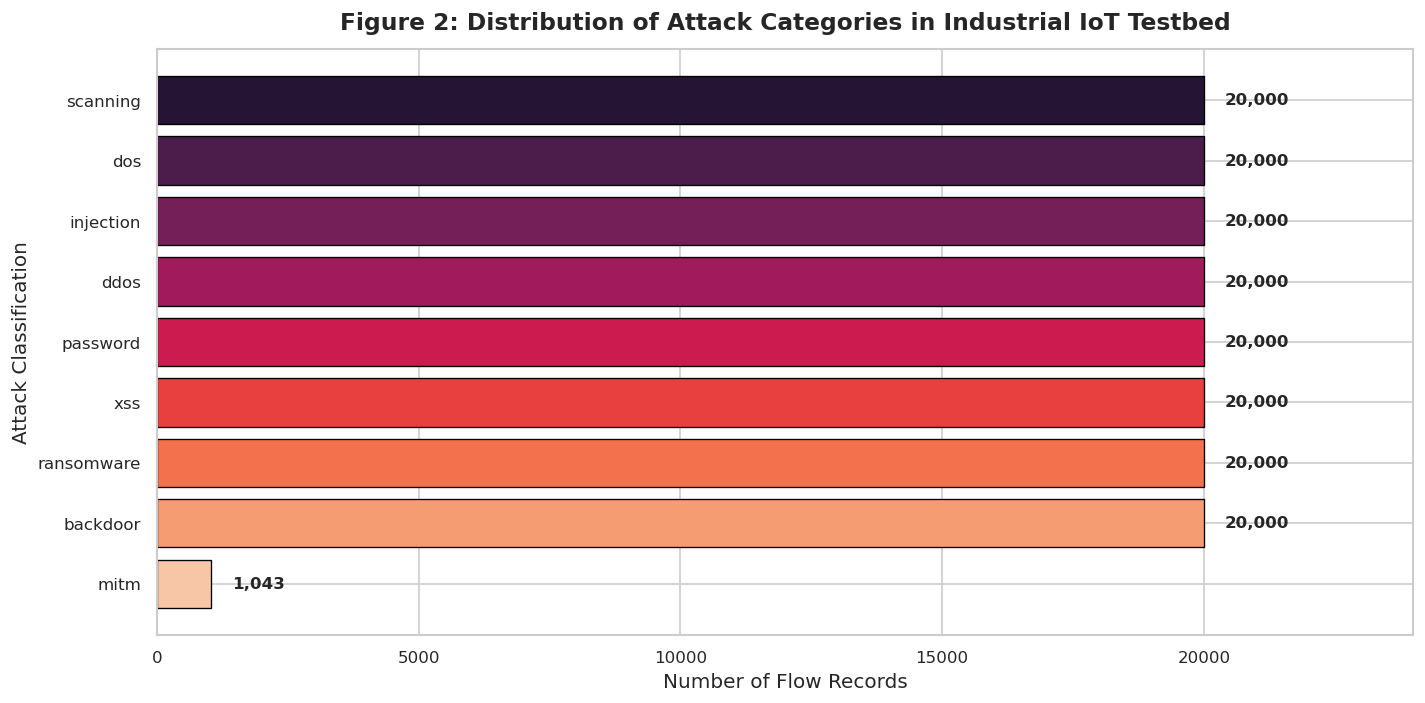

In [ ]:
# ==============================================================================
# Cell 9: Figure 2 — Multi-Class Attack Category Distribution
# Viva note: Highlighting diverse cyberattack threat vectors simulated
# ==============================================================================

plt.figure(figsize=(12, 6))

# Sort attack types (excluding normal for focused attack inspection)
attack_df = df[df['type'] != 'normal']['type'].value_counts().reset_index()
attack_df.columns = ['Attack Type', 'Count']

palette = sns.color_palette("rocket", n_colors=len(attack_df))
bars = plt.barh(attack_df['Attack Type'], attack_df['Count'], color=palette, edgecolor='black', linewidth=0.8)

plt.title('Figure 2: Distribution of Attack Categories in Industrial IoT Testbed', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Flow Records', fontsize=12)
plt.ylabel('Attack Classification', fontsize=12)
plt.xlim(0, 24000)

for bar in bars:
    wval = bar.get_width()
    plt.text(wval + 400, bar.get_y() + bar.get_height()/2.0, f"{wval:,}", ha='left', va='center', fontsize=10, fontweight='semibold')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

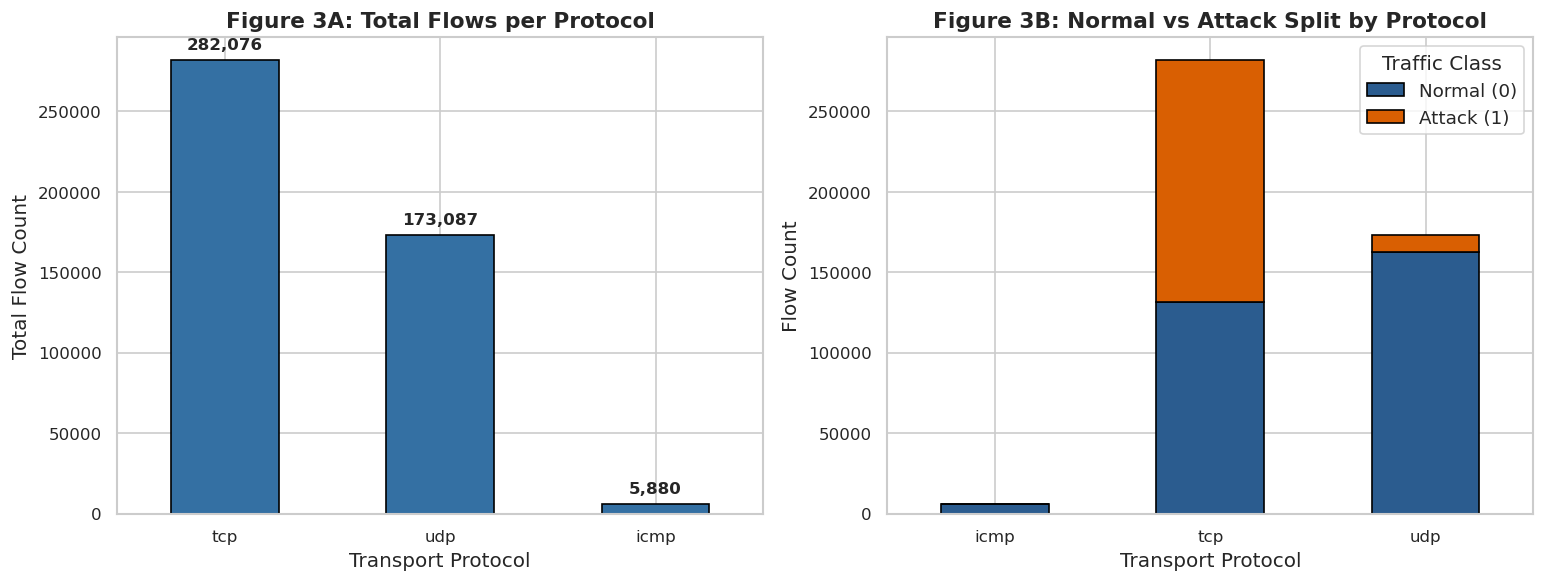

In [ ]:
# ==============================================================================
# Cell 10: Figure 3 — Transport Layer Protocols (TCP / UDP / ICMP)
# Viva note: TCP dominates stateful IIoT sessions, but UDP is vital for telemetry
# ==============================================================================

proto_class = pd.crosstab(df['proto'], df['label'], normalize='index') * 100
proto_counts = pd.crosstab(df['proto'], df['label'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Total volume by protocol
df['proto'].value_counts().plot(kind='bar', ax=ax1, color='#3470a3', edgecolor='black', linewidth=1.0)
ax1.set_title('Figure 3A: Total Flows per Protocol', fontsize=13, fontweight='bold')
ax1.set_xlabel('Transport Protocol', fontsize=12)
ax1.set_ylabel('Total Flow Count', fontsize=12)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2., p.get_height() + 5000), ha='center', va='bottom', fontsize=10, fontweight='semibold')

# Subplot 2: Normal vs Attack split within each protocol
proto_counts.plot(kind='bar', stacked=True, ax=ax2, color=['#2b5c8f', '#d95f02'], edgecolor='black', linewidth=1.0)
ax2.set_title('Figure 3B: Normal vs Attack Split by Protocol', fontsize=13, fontweight='bold')
ax2.set_xlabel('Transport Protocol', fontsize=12)
ax2.set_ylabel('Flow Count', fontsize=12)
ax2.legend(['Normal (0)', 'Attack (1)'], title='Traffic Class')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

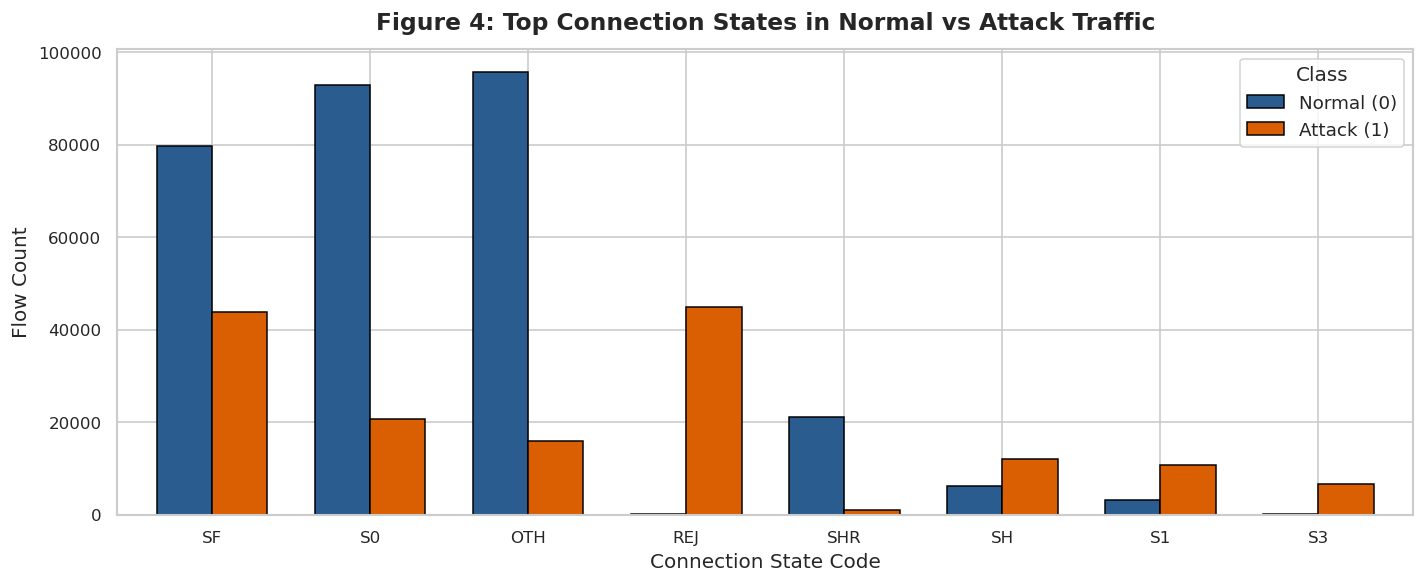

In [ ]:
# ==============================================================================
# Cell 11: Figure 4 — Connection State Analysis (conn_state)
# Viva note: S0 (SYN attempt without ACK) is a classic indicator of SYN flooding/scanning
# ==============================================================================

plt.figure(figsize=(12, 5))
top_states = df['conn_state'].value_counts().head(8).index
state_class = pd.crosstab(df[df['conn_state'].isin(top_states)]['conn_state'], df['label'])
state_class = state_class.loc[top_states]

ax = state_class.plot(kind='bar', figsize=(12, 5), color=['#2b5c8f', '#d95f02'], edgecolor='black', linewidth=0.9, width=0.7)
plt.title('Figure 4: Top Connection States in Normal vs Attack Traffic', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Connection State Code', fontsize=12)
plt.ylabel('Flow Count', fontsize=12)
plt.legend(['Normal (0)', 'Attack (1)'], title='Class')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

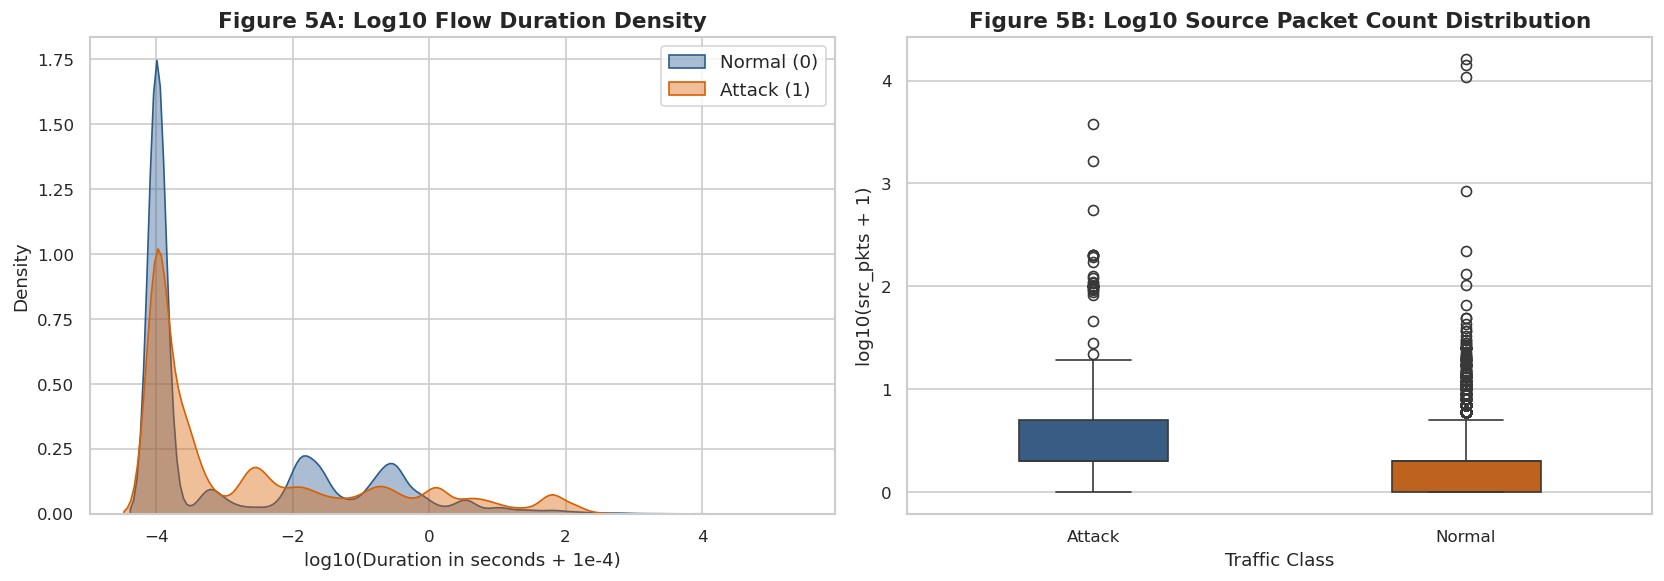

In [ ]:
# ==============================================================================
# Cell 12: Figure 5 — Traffic Flow Dynamics (Log Flow Duration & Packets)
# Viva note: Network traffic distributions are highly skewed; log-transform enables clear visual comparison
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Log Duration Distribution
normal_dur = np.log10(df[df['label'] == 0]['duration'] + 1e-4)
attack_dur = np.log10(df[df['label'] == 1]['duration'] + 1e-4)

sns.kdeplot(normal_dur, ax=ax1, label='Normal (0)', color='#2b5c8f', fill=True, alpha=0.4)
sns.kdeplot(attack_dur, ax=ax1, label='Attack (1)', color='#d95f02', fill=True, alpha=0.4)
ax1.set_title('Figure 5A: Log10 Flow Duration Density', fontsize=13, fontweight='bold')
ax1.set_xlabel('log10(Duration in seconds + 1e-4)', fontsize=11)
ax1.set_ylabel('Density', fontsize=11)
ax1.legend()

# 2. Source Packets vs Destination Packets (Log Scale Boxplots)
df_sample = df.sample(n=10000, random_state=42).copy()
df_sample['log_src_pkts'] = np.log10(df_sample['src_pkts'] + 1)
df_sample['label_str'] = df_sample['label'].map({0: 'Normal', 1: 'Attack'})

sns.boxplot(x='label_str', y='log_src_pkts', data=df_sample, ax=ax2, palette=['#2b5c8f', '#d95f02'], width=0.4)
ax2.set_title('Figure 5B: Log10 Source Packet Count Distribution', fontsize=13, fontweight='bold')
ax2.set_xlabel('Traffic Class', fontsize=11)
ax2.set_ylabel('log10(src_pkts + 1)', fontsize=11)

plt.tight_layout()
plt.show()

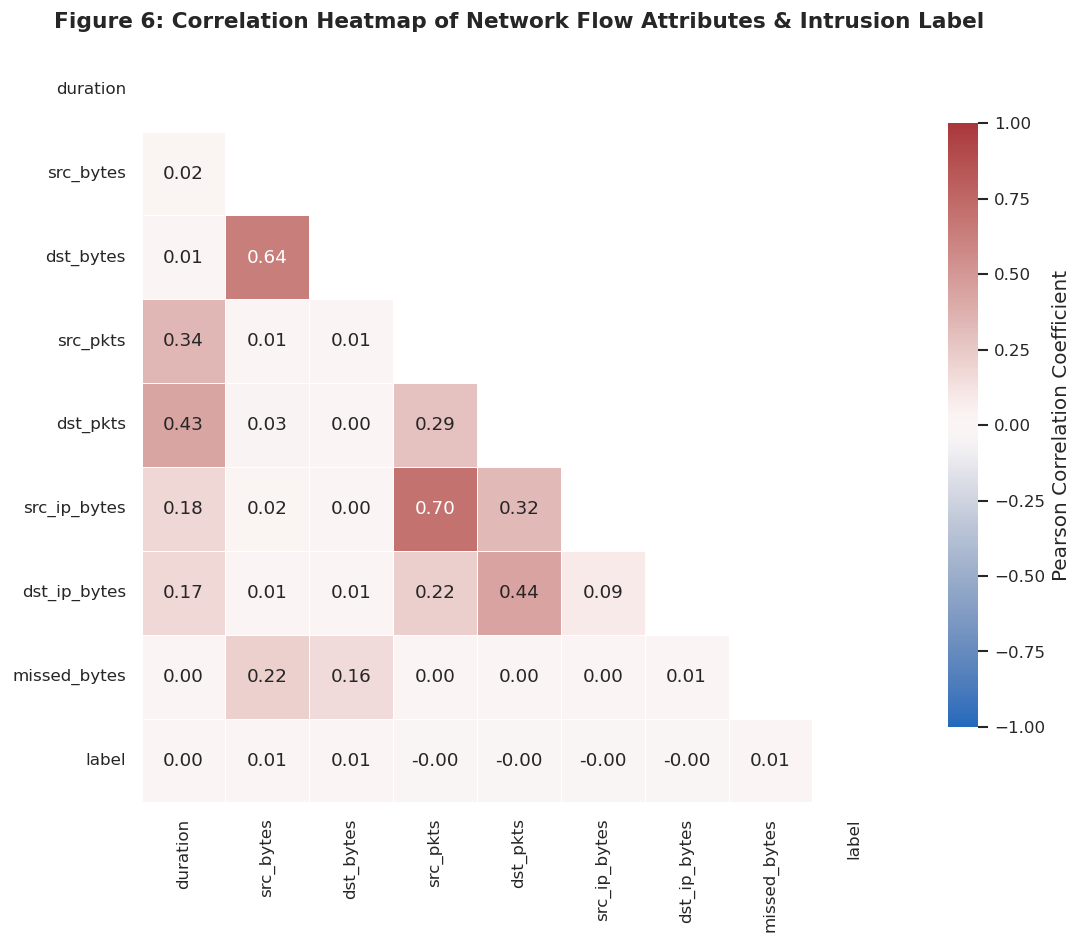

In [ ]:
# ==============================================================================
# Cell 13: Figure 6 — Correlation Matrix Heatmap of Flow Metrics
# Viva note: Multicollinearity check (e.g. between src_pkts and src_ip_bytes)
# ==============================================================================

plt.figure(figsize=(10, 8))
corr_cols = ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'src_ip_bytes', 'dst_ip_bytes', 'missed_bytes', 'label']
corr_matrix = df[corr_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title('Figure 6: Correlation Heatmap of Network Flow Attributes & Intrusion Label', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

---
## 10. Viva Voce Examination Defense Guide (Key Technical Takeaways)

This section prepares the student for questions asked by external examiners, faculty coordinators, and evaluation committees during project review:

### Q1: What dataset are we using and what is its provenance?
- **Answer:** We are utilizing the **TON_IoT Network Flow Dataset**, created by the Cyber Range Lab of UNSW Canberra Cyber at the Australian Defence Force Academy. It is an industry-standard benchmark generated from an emulation of an Industry 4.0 IoT network integrating industrial automation, smart sensors (temperature, light, Modbus, MQTT), and cloud services. It captures both normal traffic and 9 modern cyberattack scenarios.

### Q2: Why are network flow records preferred over raw PCAP packet dumps for ML/DL?
- **Answer:** Raw PCAP files contain full packet payloads (headers + raw byte contents), which:
  1. Have variable length, requiring complex byte sequence modeling.
  2. Frequently contain encrypted payloads (TLS/HTTPS), where deep packet inspection (DPI) fails.
  3. Impose unacceptable storage and compute overhead in high-throughput industrial networks (gigabits/sec).
  Flow records (generated by network monitors such as Zeek or Argus) aggregate packet statistics into concise, bidirectional flow summaries (duration, byte counts, packet counts, connection state) which can be evaluated in near-real-time by lightweight neural networks.

### Q3: What is the class distribution, and why is accuracy an insufficient evaluation metric?
- **Answer:** The dataset comprises **300,000 Normal flows (65.07%)** and **161,043 Attack flows (34.93%)**. While more balanced than real-world traffic (where attacks are often <1%), class imbalance is still significant.
  - In security operations, **Recall (Detection Rate / Sensitivity)** is the most crucial metric: failing to detect a cyberattack (False Negative) can result in physical destruction of industrial equipment (e.g. Stuxnet-style PLC manipulation), whereas a False Positive merely prompts a security analyst review.
  - Hence, models in subsequent phases must be evaluated using **Precision, Recall, F1-Score, and False Positive Rate (FPR)**, rather than raw Accuracy.

### Q4: Why are there no NaN values in Pandas, yet thousands of `'-'` entries? How will we handle them in Preprocessing (Phase 2)?
- **Answer:** Zeek/Bro logs encode absent or non-applicable protocol attributes as hyphens (`'-'`). For instance, a flow that uses the DNS protocol does not generate HTTP methods (`http_method`), and UDP flows do not establish TCP flags.
  - In Phase 2 (`src/preprocess.py`), we will replace `'-'` with a dedicated token (e.g. `'none'` or `'not_applicable'`) for categorical variables, or impute `0` for numeric fields, and drop ultra-sparse columns with >99% non-applicable entries.

### Q5: Why must IP addresses (`src_ip`, `dst_ip`) and timestamps (`ts`) be excluded from model training?
- **Answer:** Including IP addresses and timestamps causes **data leakage and memorization**:
  - The model would simply memorize which specific IP addresses launched attacks in the testbed (e.g. `192.168.1.152`), rather than learning the statistical signatures of malicious flow patterns.
  - In a real-world deployment, attackers use dynamic IPs and spoofing; excluding static identifiers ensures the trained neural network generalizes to unseen networks.

---
**Phase 1 Status:** Completed (Data Ingestion, Verification, and Exploratory Analysis Complete. Ready for Phase 2 Preprocessing Pipeline).